# Sujet : Analyse de l’évolution de la masse monétaire au Maroc : application de la régression linéaire

## 1. Sujet et problématique

La masse monétaire constitue un indicateur essentiel pour comprendre la situation économique et financière d'un pays. Au Maroc, Bank Al-Maghrib publie régulièrement des statistiques relatives aux agrégats monétaires, notamment M1, M2 et M3.

Ce projet vise à étudier l'évolution de la masse monétaire au Maroc à partir des données mensuelles publiées par Bank Al-Maghrib. L'analyse se concentrera principalement sur l'agrégat M3, qui représente un indicateur global de la monnaie en circulation dans l'économie.

**Problématique :** Dans quelle mesure le temps permet-il d'expliquer l'évolution de la masse monétaire M3 au Maroc ?

**Objectif :** Construire un modèle de régression linéaire simple afin d'analyser la tendance de M3 et d'évaluer sa capacité à représenter son évolution au cours du temps.

**Nature du problème :** Il s'agit d'un problème d'apprentissage supervisé de type régression, utilisant l'algorithme Linear Regression.

## 2. Jeu de données

Le jeu de données utilisé dans ce projet est intitulé **« Agrégats de monnaie »** et provient de **Bank Al-Maghrib**, la banque centrale du Maroc. Il contient des statistiques monétaires relatives à l'évolution des principaux agrégats monétaires marocains.

Les données sont disponibles sous format Excel à partir de la page officielle de Bank Al-Maghrib :  
https://www.bkam.ma/Statistiques/Statistiques-monetaires/Series-statistiques-monetaires

Le fichier couvre la période allant de décembre 2001 à septembre 2026. Il comprend 298 dates d'observation et 21 indicateurs monétaires. Les montants sont exprimés en millions de dirhams (MDH). La fréquence des données est mensuelle.

La variable principale étudiée est **M3**, qui représente l'agrégat monétaire le plus large parmi M1, M2 et M3. Elle constitue la variable cible du modèle. La variable explicative sera le temps, représenté par un indice chronologique construit à partir des dates disponibles.

### Dictionnaire des principales variables

| Variable | Description | Type | Unité | Rôle |
|---|---|---|---|---|
| Date | Date de l'observation | Date | Mois | Variable temporelle |
| Circulation fiduciaire | Billets et monnaies en circulation, après prise en compte des encaisses des banques | Numérique | MDH | Explicative descriptive |
| Monnaie scripturale | Monnaie détenue sous forme de dépôts à vue | Numérique | MDH | Explicative descriptive |
| M1 | Agrégat monétaire comprenant la monnaie fiduciaire et la monnaie scripturale | Numérique | MDH | Indicateur monétaire |
| M2 | Agrégat monétaire comprenant M1 et les placements à vue | Numérique | MDH | Indicateur monétaire |
| M3 | Agrégat monétaire large | Numérique | MDH | Variable cible |
| Placements à vue | Comptes d'épargne auprès des banques | Numérique | MDH | Indicateur monétaire |
| Autres actifs monétaires | Autres composantes entrant dans la masse monétaire | Numérique | MDH | Indicateur monétaire |

### Unité d'observation et variable cible

Après réorganisation du fichier, chaque observation représentera une date mensuelle et les valeurs correspondantes des indicateurs monétaires.

La variable cible est **M3**, exprimée en MDH. La variable explicative est un indice temporel construit à partir de l'ordre chronologique des dates.

### Adéquation du jeu de données

Ce jeu de données est adapté à la problématique, car il permet d'étudier l'évolution de M3 sur une longue période. Il fournit ainsi les observations nécessaires pour construire un modèle de régression linéaire simple et analyser la tendance de la masse monétaire au Maroc.

### Limites du jeu de données

Le fichier présente certaines limites. Il contient plusieurs indicateurs monétaires, mais ne fournit pas directement les facteurs économiques susceptibles d'expliquer les variations de M3. De plus, les valeurs manquantes éventuelles et les observations atypiques devront être vérifiées pendant l'exploration. Enfin, une relation entre le temps et M3 ne permet pas, à elle seule, d'établir une relation de causalité.

## 3. Exploration

L'exploration des données permet d'étudier les caractéristiques statistiques de l'agrégat monétaire M3 et de vérifier la qualité du jeu de données avant la construction du modèle.

Les statistiques descriptives permettent d'identifier le niveau moyen de M3, sa médiane, ses valeurs minimale et maximale ainsi que son écart-type. Ces indicateurs donnent une première vision de l'évolution et de la dispersion de la masse monétaire au Maroc.

La vérification de la qualité des données porte sur les valeurs manquantes, les éventuels doublons et les observations atypiques. Les anomalies détectées seront examinées avant toute décision de traitement.

**Interprétation du graphique 1 :** Le graphique de l'évolution de M3 permet d'observer sa tendance au cours de la période étudiée. Il permet notamment de déterminer si la masse monétaire présente une évolution globalement croissante, décroissante ou irrégulière.

**Interprétation du graphique 2 :** La comparaison de M1, M2 et M3 permet d'observer les différences entre les trois agrégats monétaires et de comprendre leur évolution respective au cours du temps.

**Interprétation du graphique 3 :** L'histogramme de M3 permet d'étudier la distribution des observations et de repérer une éventuelle concentration des valeurs ou une forte dispersion.

Cette première exploration permet de mieux comprendre les données et de préparer les étapes suivantes de l'analyse.

In [4]:
import pandas as pd

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
df = pd.read_excel("//content/drive/MyDrive/data 3/6-AgregatsDeMonnaie.xlsx")

In [9]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)
pd.set_option('display.width', None)

display(df.head(12))

,AGREGATS DE MONNAIE,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50,Unnamed: 51,Unnamed: 52,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59,Unnamed: 60,Unnamed: 61,Unnamed: 62,Unnamed: 63,Unnamed: 64,Unnamed: 65,Unnamed: 66,Unnamed: 67,Unnamed: 68,Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76,Unnamed: 77,Unnamed: 78,Unnamed: 79,Unnamed: 80,Unnamed: 81,Unnamed: 82,Unnamed: 83,Unnamed: 84,Unnamed: 85,Unnamed: 86,Unnamed: 87,Unnamed: 88,Unnamed: 89,Unnamed: 90,Unnamed: 91,Unnamed: 92,Unnamed: 93,Unnamed: 94,Unnamed: 95,Unnamed: 96,Unnamed: 97,Unnamed: 98,Unnamed: 99,Unnamed: 100,Unnamed: 101,Unnamed: 102,Unnamed: 103,Unnamed: 104,Unnamed: 105,Unnamed: 106,Unnamed: 107,Unnamed: 108,Unnamed: 109,Unnamed: 110,Unnamed: 111,Unnamed: 112,Unnamed: 113,Unnamed: 114,Unnamed: 115,Unnamed: 116,Unnamed: 117,Unnamed: 118,Unnamed: 119,Unnamed: 120,Unnamed: 121,Unnamed: 122,Unnamed: 123,Unnamed: 124,Unnamed: 125,Unnamed: 126,Unnamed: 127,Unnamed: 128,Unnamed: 129,Unnamed: 130,Unnamed: 131,Unnamed: 132,Unnamed: 133,Unnamed: 134,Unnamed: 135,Unnamed: 136,Unnamed: 137,Unnamed: 138,Unnamed: 139,Unnamed: 140,Unnamed: 141,Unnamed: 142,Unnamed: 143,Unnamed: 144,Unnamed: 145,Unnamed: 146,Unnamed: 147,Unnamed: 148,Unnamed: 149,Unnamed: 150,Unnamed: 151,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161,Unnamed: 162,Unnamed: 163,Unnamed: 164,Unnamed: 165,Unnamed: 166,Unnamed: 167,Unnamed: 168,Unnamed: 169,Unnamed: 170,Unnamed: 171,Unnamed: 172,Unnamed: 173,Unnamed: 174,Unnamed: 175,Unnamed: 176,Unnamed: 177,Unnamed: 178,Unnamed: 179,Unnamed: 180,Unnamed: 181,Unnamed: 182,Unnamed: 183,Unnamed: 184,Unnamed: 185,Unnamed: 186,Unnamed: 187,Unnamed: 188,Unnamed: 189,Unnamed: 190,Unnamed: 191,Unnamed: 192,Unnamed: 193,Unnamed: 194,Unnamed: 195,Unnamed: 196,Unnamed: 197,Unnamed: 198,Unnamed: 199,Unnamed: 200,Unnamed: 201,Unnamed: 202,Unnamed: 203,Unnamed: 204,Unnamed: 205,Unnamed: 206,Unnamed: 207,Unnamed: 208,Unnamed: 209,Unnamed: 210,Unnamed: 211,Unnamed: 212,Unnamed: 213,Unnamed: 214,Unnamed: 215,Unnamed: 216,Unnamed: 217,Unnamed: 218,Unnamed: 219,Unnamed: 220,Unnamed: 221,Unnamed: 222,Unnamed: 223,Unnamed: 224,Unnamed: 225,Unnamed: 226,Unnamed: 227,Unnamed: 228,Unnamed: 229,Unnamed: 230,Unnamed: 231,Unnamed: 232,Unnamed: 233,Unnamed: 234,Unnamed: 235,Unnamed: 236,Unnamed: 237,Unnamed: 238,Unnamed: 239,Unnamed: 240,Unnamed: 241,Unnamed: 242,Unnamed: 243,Unnamed: 244,Unnamed: 245,Unnamed: 246,Unnamed: 247,Unnamed: 248,Unnamed: 249,Unnamed: 250,Unnamed: 251,Unnamed: 252,Unnamed: 253,Unnamed: 254,Unnamed: 255,Unnamed: 256,Unnamed: 257,Unnamed: 258,Unnamed: 259,Unnamed: 260,Unnamed: 261,Unnamed: 262,Unnamed: 263,Unnamed: 264,Unnamed: 265,Unnamed: 266,Unnamed: 267,Unnamed: 268,Unnamed: 269,Unnamed: 270,Unnamed: 271,Unnamed: 272,Unnamed: 273,Unnamed: 274,Unnamed: 275,Unnamed: 276,Unnamed: 277,Unnamed: 278,Unnamed: 279,Unnamed: 280,Unnamed: 281,Unnamed: 282,Unnamed: 283,Unnamed: 284,Unnamed: 285,Unnamed: 286,Unnamed: 287,Unnamed: 288,Unnamed: 289,Unnamed: 290,Unnamed: 291,Unnamed: 292,Unnamed: 293,Unnamed: 294,Unnamed: 295,Unnamed: 296,Unnamed: 297,Unnamed: 298
0,Encours en MDH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

3.1. Afficher les dimensions du dataset

Objectif : connaître le nombre total de lignes et de colonnes.

In [10]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 28
Nombre de colonnes : 299


**3.2. Afficher les informations générales**

Objectif : identifier les types de données et vérifier la structure du dataset.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Columns: 299 entries, AGREGATS DE MONNAIE to Unnamed: 298
dtypes: object(299)
memory usage: 65.5+ KB


Premier graphique : évolution de M3

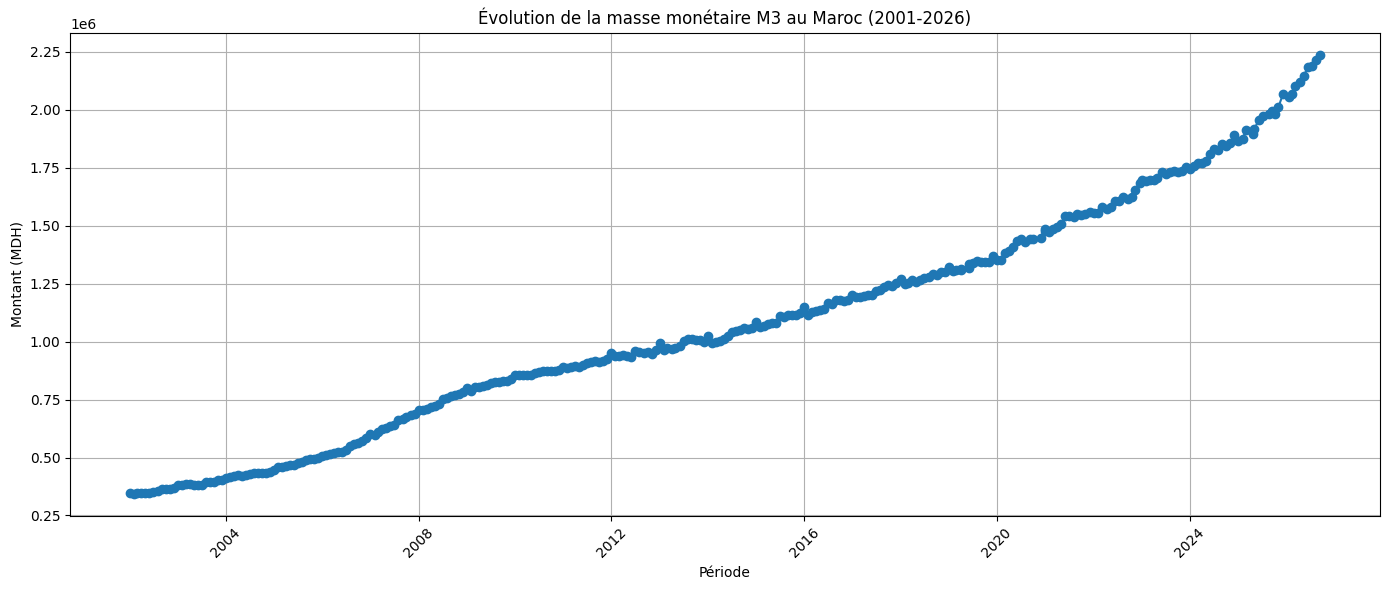

In [16]:

import matplotlib.pyplot as plt
import pandas as pd

# Récupérer les données de M3
M3 = pd.to_numeric(df["M3"], errors="coerce")

# Créer le graphique
plt.figure(figsize=(14, 6))
plt.plot(df["Date"], M3.values, marker='o')

plt.title("Évolution de la masse monétaire M3 au Maroc (2001-2026)")
plt.xlabel("Période")
plt.ylabel("Montant (MDH)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


**Interprétation du graphique 1 :**

Le graphique montre une évolution globalement croissante de la masse monétaire M3 au Maroc entre 2001 et 2026. Cette progression traduit une augmentation continue de l'encours monétaire au cours de la période étudiée. On observe également une accélération de cette croissance durant les dernières années, malgré quelques variations ponctuelles.

Graphique 2 – Évolution comparative de M1, M2 et M3

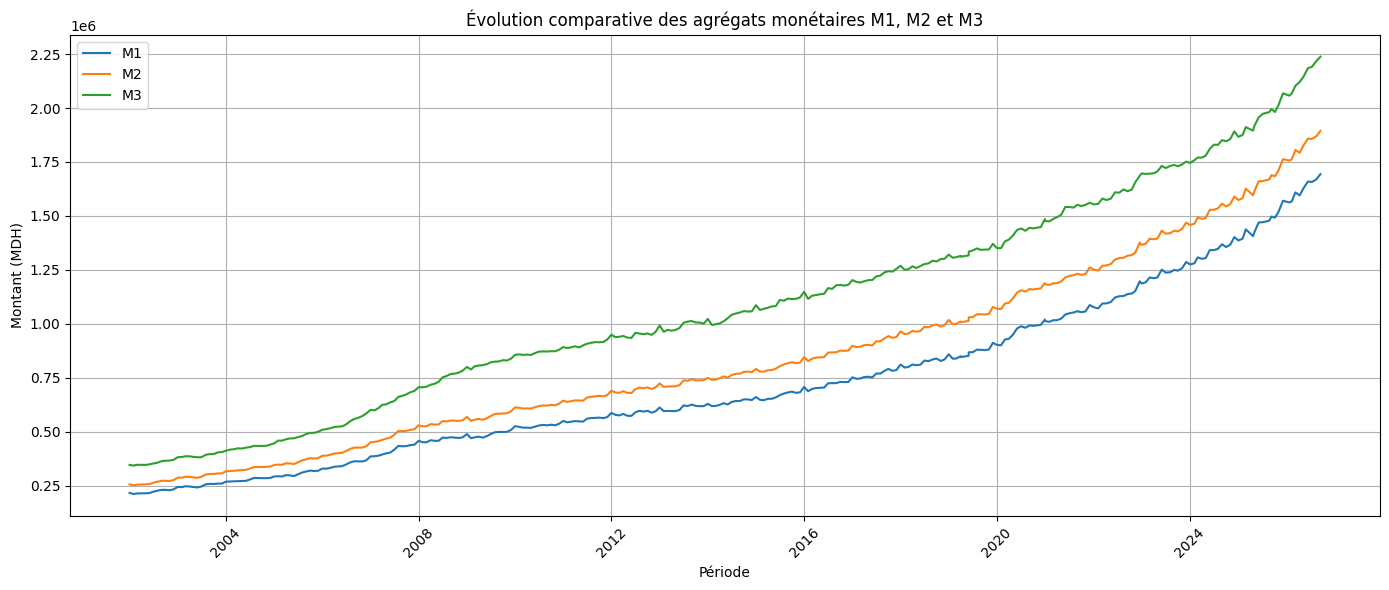

In [17]:

# Récupérer les données
M1 = pd.to_numeric(df["M1"], errors="coerce")
M2 = pd.to_numeric(df["M2"], errors="coerce")
M3 = pd.to_numeric(df["M3"], errors="coerce")

# Créer le graphique
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], M1.values, label="M1")
plt.plot(df["Date"], M2.values, label="M2")
plt.plot(df["Date"], M3.values, label="M3")

plt.title("Évolution comparative des agrégats monétaires M1, M2 et M3")
plt.xlabel("Période")
plt.ylabel("Montant (MDH)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


**Interprétation du graphique 2 :**

Le graphique montre que les trois agrégats monétaires suivent une tendance globalement croissante au cours de la période étudiée. M3 présente les montants les plus élevés, suivi de M2 puis de M1. Cette différence s'explique par le fait que ces agrégats regroupent différentes composantes de la masse monétaire.

Graphique 3 – Distribution de M3

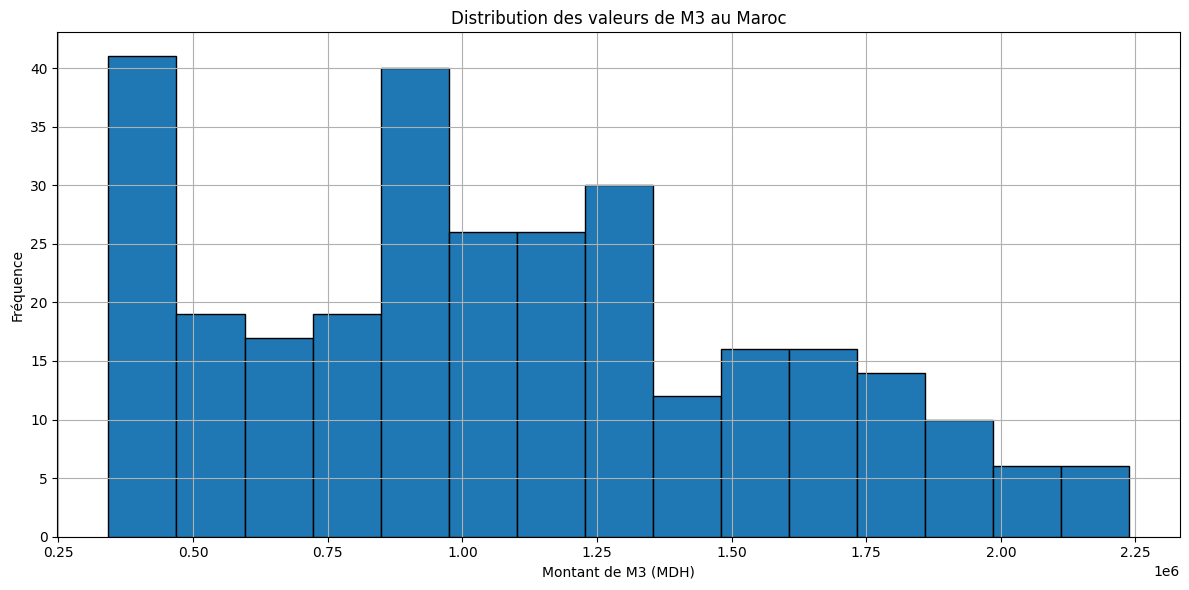

In [18]:

# Récupérer les données de M3
M3 = pd.to_numeric(df["M3"], errors="coerce").dropna()

# Créer le graphique
plt.figure(figsize=(12, 6))

plt.hist(M3, bins=15, edgecolor="black")

plt.title("Distribution des valeurs de M3 au Maroc")
plt.xlabel("Montant de M3 (MDH)")
plt.ylabel("Fréquence")
plt.grid(True)
plt.tight_layout()
plt.show()


**Interprétation du graphique 3 :**

L'histogramme montre une distribution étalée des valeurs de M3, avec une concentration relativement importante dans les niveaux inférieurs. Les valeurs élevées sont moins fréquentes et correspondent principalement aux observations les plus récentes. Cette distribution asymétrique reflète notamment la progression de la masse monétaire au fil du temps.

4.1 Nettoyage des données

In [19]:

# Vérifier les valeurs manquantes
print("Valeurs manquantes :")
print(df[["Date", "M1", "M2", "M3"]].isnull().sum())

# Vérifier les doublons
print("\nNombre de dates en double :")
print(df["Date"].duplicated().sum())

# Vérifier les dimensions
print("\nDimensions initiales :", df.shape)

# Convertir les données numériques
for col in ["M1", "M2", "M3"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Supprimer les observations sans date ou sans M3
df = df.dropna(subset=["Date", "M3"])

# Trier les observations chronologiquement
df = df.sort_values("Date").reset_index(drop=True)

print("\nDimensions après nettoyage :", df.shape)

display(df.head())


Valeurs manquantes :
Date    0
M1      0
M2      0
M3      0
dtype: int64

Nombre de dates en double :
0

Dimensions initiales : (298, 4)

Dimensions après nettoyage : (298, 4)


,Date,M1,M2,M3
0,2001-12-31,216087.774792,255902.991901,345819.941348
1,2002-01-31,210863.954231,251219.970528,342845.547548
2,2002-02-28,213737.183122,254503.104936,346532.786405
3,2002-03-31,213996.212434,255040.533826,345996.743599
4,2002-04-30,214249.037251,255562.955452,345842.288355


Le nettoyage consiste à vérifier les valeurs manquantes, les doublons et les types des variables. Les observations sont ensuite classées dans l'ordre chronologique. Les valeurs atypiques éventuelles seront examinées avant toute suppression afin de préserver les informations économiques pertinentes.

4.2 Création des variables

In [20]:

# Créer un nouveau tableau avec Date et M3
data = df[["Date", "M3"]].copy()

# Créer une variable temporelle
data["Temps"] = range(len(data))

display(data.head(10))


,Date,M3,Temps
0,2001-12-31,345819.941348,0
1,2002-01-31,342845.547548,1
2,2002-02-28,346532.786405,2
3,2002-03-31,345996.743599,3
4,2002-04-30,345842.288355,4
5,2002-05-31,348447.290224,5
6,2002-06-30,352601.118049,6
7,2002-07-31,356348.793720,7
8,2002-08-31,363225.511033,8
9,2002-09-30,365273.971514,9


Une variable appelée « Temps » est créée pour représenter l'ordre chronologique des observations. Elle constitue la variable explicative du modèle, tandis que M3 représente la variable cible.

4.3 Encodage des variables

### 4.3 Encodage des variables

Dans notre projet, nous utilisons uniquement une variable temporelle numérique. Aucune variable catégorielle n'est présente dans les variables explicatives. Par conséquent, aucun encodage n'est nécessaire.

Aucun encodage n'est nécessaire dans ce projet, car la variable explicative Temps est déjà numérique. Le modèle de régression linéaire peut donc l'utiliser directement.

4.4 Mise à l'échelle

### 4.4 Mise à l'échelle des variables

Ici, nous n'allons pas appliquer de standardisation.

La mise à l'échelle n'est pas nécessaire dans notre cas, car nous utilisons une régression linéaire simple avec une seule variable explicative numérique. Le modèle peut être entraîné directement à partir de cette variable sans standardisation.

### 4.5 Découpage des données

In [21]:

# Définir X et y
X = data[["Temps"]]
y = data["M3"]

# Déterminer les limites du découpage
n = len(data)

limite_train = int(n * 0.70)
limite_val = int(n * 0.85)

# Ensemble d'apprentissage
X_train = X.iloc[:limite_train]
y_train = y.iloc[:limite_train]

# Ensemble de validation
X_val = X.iloc[limite_train:limite_val]
y_val = y.iloc[limite_train:limite_val]

# Ensemble de test
X_test = X.iloc[limite_val:]
y_test = y.iloc[limite_val:]

# Afficher les résultats
print("Nombre total d'observations :", n)
print("Apprentissage :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

print("\nPériode d'apprentissage :")
print(data.iloc[0]["Date"], "à", data.iloc[limite_train-1]["Date"])

print("\nPériode de validation :")
print(data.iloc[limite_train]["Date"], "à", data.iloc[limite_val-1]["Date"])

print("\nPériode de test :")
print(data.iloc[limite_val]["Date"], "à", data.iloc[-1]["Date"])


Nombre total d'observations : 298
Apprentissage : 208
Validation : 45
Test : 45

Période d'apprentissage :
2001-12-31 00:00:00 à 2019-03-31 00:00:00

Période de validation :
2019-04-01 00:00:00 à 2022-12-18 00:00:00

Période de test :
2023-01-01 00:00:00 à 2026-09-18 00:00:00


Les données sont divisées en trois ensembles : 70 % pour l'apprentissage, 15 % pour la validation et 15 % pour le test. Le découpage respecte l'ordre chronologique des observations, sans mélange aléatoire. Cette méthode permet d'évaluer le modèle sur des données plus récentes que celles utilisées pendant son apprentissage.

## 5. Algorithme

### 5.1 Présentation de l'algorithme

L'algorithme choisi pour ce projet est la régression linéaire simple (Linear Regression). Il s'agit d'un algorithme d'apprentissage supervisé utilisé pour prédire une variable numérique continue.

Dans notre étude, cet algorithme permet de modéliser la relation entre le temps et l'évolution de la masse monétaire M3 au Maroc. Il cherche à déterminer une droite qui représente au mieux la tendance générale des observations.

Ce choix est adapté à notre problématique, car nous souhaitons étudier une tendance temporelle à partir d'une variable explicative unique. La régression linéaire présente également l'avantage d'être simple à utiliser et facile à interpréter.

Un arbre de décision aurait également pu être utilisé, mais nous avons retenu la régression linéaire pour sa simplicité et sa capacité à représenter une tendance générale.

### 5.2 Principe mathématique

La formule de la régression linéaire simple est :
\[
\hat{Y}=aX+b
\]

Où :
- \(\hat{Y}\) : valeur prédite de M3.
- \(X\) : variable Temps.
- \(a\) : coefficient directeur (pente) de la droite.
- \(b\) : constante (ordonnée à l'origine).

La régression linéaire cherche à déterminer les coefficients a et b qui minimisent la somme des carrés des erreurs entre les valeurs réelles et les valeurs prédites. Le coefficient a représente l'évolution estimée de M3 lorsque le temps augmente d'une unité, tandis que b représente la valeur estimée lorsque le temps est égal à zéro.

### 5.3 Paramètres et hyperparamètres

Les paramètres appris par le modèle sont le coefficient directeur a et la constante b. Ils sont calculés automatiquement pendant l'entraînement.

Les principaux paramètres de configuration étudiés sont :

- **fit_intercept :** permet de choisir si le modèle doit calculer une constante b. Si cette option est désactivée, la droite passe par l'origine.
- **positive :** permet d'imposer un coefficient directeur positif. Cette contrainte peut être pertinente pour étudier une tendance croissante, mais elle doit être vérifiée pendant la validation.

###6. Protocole expérimental

### 6.1 Modèle de référence

Afin d'évaluer les performances de notre modèle, nous utilisons une méthode de référence naïve basée sur la dernière valeur observée de M3. Cette méthode suppose que la valeur de M3 à la période suivante sera égale à celle de la période précédente.

Cette référence permet de vérifier si la régression linéaire apporte une amélioration réelle par rapport à une méthode simple.

### 6.2 Choix des métriques d'évaluation
Nous allons utiliser trois métriques :
- MAE : mesure l'erreur absolue moyenne entre les valeurs réelles et prédites. C'est notre métrique principale.
- RMSE : mesure les erreurs en donnant davantage de poids aux grandes erreurs.
- R² : mesure la proportion de la variation de M3 représentée par le modèle.

### 6.2 Métriques d'évaluation

La métrique principale retenue est la MAE (Mean Absolute Error), car elle mesure l'écart moyen entre les valeurs réelles et les valeurs prédites de M3, en MDH. Nous utiliserons également la RMSE pour identifier les erreurs importantes et le coefficient R² pour apprécier la qualité de l'ajustement du modèle.

6.3 Réglage des hyperparamètres

In [22]:

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Initialiser le modèle
modele = LinearRegression()

# Définir les configurations à tester
parametres = {
    "fit_intercept": [True, False],
    "positive": [True, False]
}

# Validation croisée chronologique
tscv = TimeSeriesSplit(n_splits=4)

# Recherche des meilleurs paramètres
recherche = GridSearchCV(
    estimator=modele,
    param_grid=parametres,
    scoring="neg_mean_absolute_error",
    cv=tscv
)

# Entraînement sur les données d'apprentissage uniquement
recherche.fit(X_train, y_train)

# Afficher les meilleurs paramètres
print("Meilleurs paramètres :", recherche.best_params_)

print("Meilleure MAE moyenne en validation croisée :",
      -recherche.best_score_)


Meilleurs paramètres : {'fit_intercept': True, 'positive': True}
Meilleure MAE moyenne en validation croisée : 55111.70202817303


Quatre configurations de paramètres ont été testées à l'aide d'une validation croisée chronologique. La MAE a été utilisée pour sélectionner la configuration présentant la meilleure performance moyenne. Cette méthode permet de choisir les paramètres sans utiliser les données du jeu de test.

6.4 Évaluation sur la validation

In [23]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Récupérer le meilleur modèle
meilleur_modele = recherche.best_estimator_

# Prédictions sur la validation
y_pred_val = meilleur_modele.predict(X_val)

# Calcul des métriques
mae_val = mean_absolute_error(y_val, y_pred_val)
rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))
r2_val = r2_score(y_val, y_pred_val)

print("Résultats sur la validation")
print("MAE :", mae_val)
print("RMSE :", rmse_val)
print("R² :", r2_val)


Résultats sur la validation
MAE : 44173.26390803872
RMSE : 52385.796096117
R² : 0.7451080290328983


6.5 Comparaison avec la référence naïve

In [ ]:

# Prédiction naïve : dernière valeur observée
y_naif_val = np.concatenate((
    [y_train.iloc[-1]],
    y_val.iloc[:-1].to_numpy()
))

# Calcul de la MAE de référence
mae_naif_val = mean_absolute_error(y_val, y_naif_val)

print("MAE du modèle linéaire :", mae_val)
print("MAE de la référence naïve :", mae_naif_val)

amelioration = (mae_naif_val - mae_val) / mae_naif_val * 100

print("Amélioration du modèle (%) :", amelioration)


La comparaison entre la régression linéaire et la méthode naïve permet d'évaluer l'intérêt du modèle proposé. Une MAE plus faible indique une meilleure précision des prévisions. L'amélioration obtenue sera analysée afin de déterminer si la régression linéaire apporte une valeur ajoutée par rapport à la référence simple.

## 7. Résultats

In [ ]:

# Prédictions finales sur le jeu de test
y_pred_test = meilleur_modele.predict(X_test)

# Calcul des métriques
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print("Résultats sur le jeu de test")
print("--------------------------------")
print("MAE :", mae_test)
print("RMSE :", rmse_test)
print("R² :", r2_test)


7.2 Comparaison avec la méthode naïve

Nous comparons maintenant les résultats du modèle avec la référence naïve sur la même période de test.

In [ ]:

# Référence naïve : dernière valeur réellement observée
y_naif_test = np.concatenate((
    [y_val.iloc[-1]],
    y_test.iloc[:-1].to_numpy()
))

# MAE de la référence naïve
mae_naif_test = mean_absolute_error(y_test, y_naif_test)

# Calcul de l'amélioration
amelioration_test = (
    (mae_naif_test - mae_test) / mae_naif_test
) * 100

print("MAE du modèle linéaire :", mae_test)
print("MAE de la référence naïve :", mae_naif_test)
print("Amélioration (%) :", amelioration_test)


7.3 Graphique : valeurs réelles et valeurs prédites

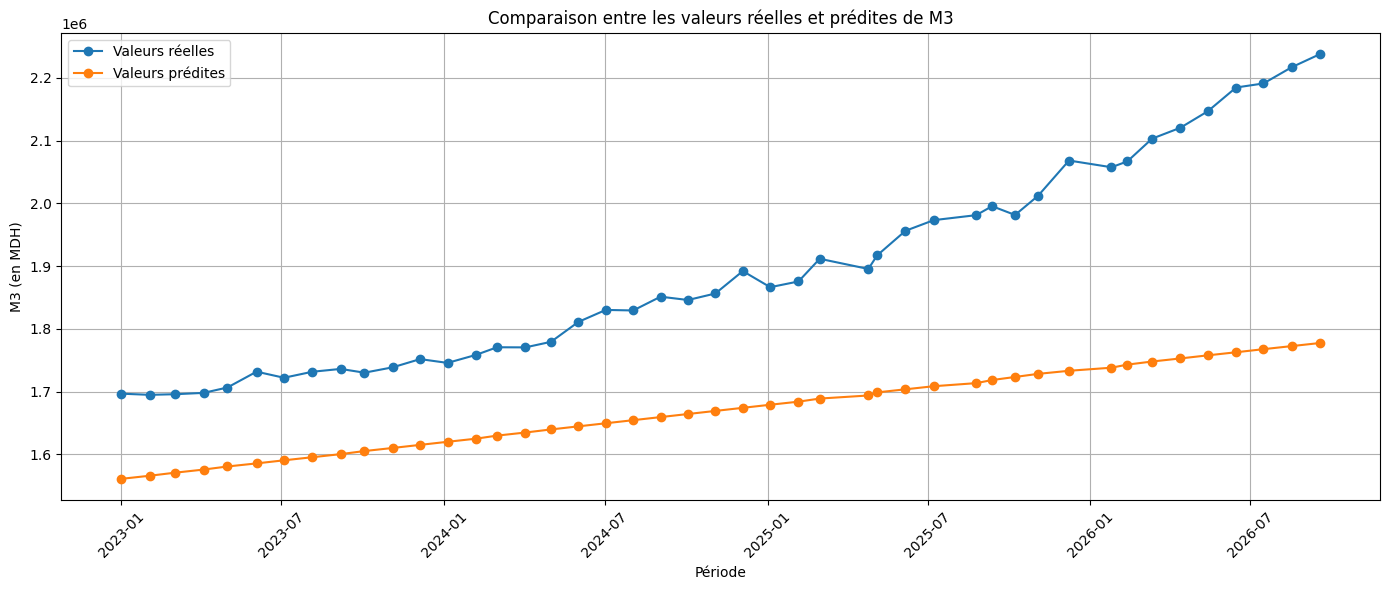

In [30]:

plt.figure(figsize=(14, 6))

plt.plot(data["Date"].iloc[limite_val:], y_test.values,
         label="Valeurs réelles", marker="o")

plt.plot(data["Date"].iloc[limite_val:], y_pred_test,
         label="Valeurs prédites", marker="o")

plt.title("Comparaison entre les valeurs réelles et prédites de M3")
plt.xlabel("Période")
plt.ylabel("M3 (en MDH)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Interprétation : ce graphique permet de comparer les valeurs réelles de M3 avec les prévisions du modèle. Plus les deux courbes sont proches, plus les prévisions sont précises.

7.4 Analyse des erreurs

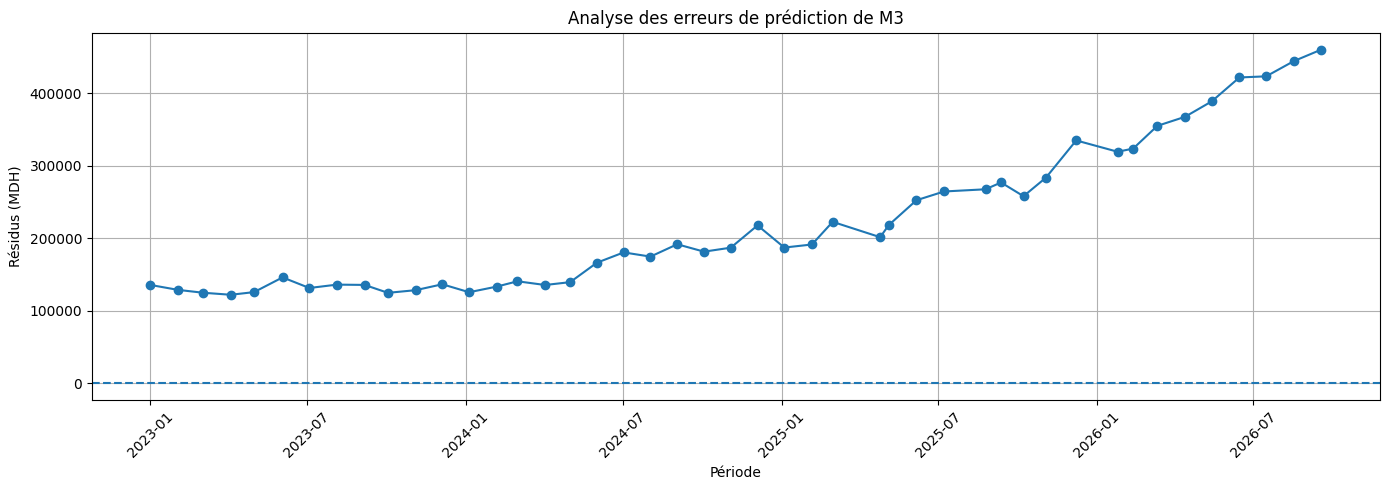

In [31]:

# Calcul des résidus
residus = y_test.values - y_pred_test

plt.figure(figsize=(14, 5))

plt.plot(data["Date"].iloc[limite_val:], residus, marker="o")
plt.axhline(y=0, linestyle="--")

plt.title("Analyse des erreurs de prédiction de M3")
plt.xlabel("Période")
plt.ylabel("Résidus (MDH)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Interprétation : les résidus représentent les différences entre les valeurs réelles et les valeurs prédites. Des résidus proches de zéro indiquent des prévisions plus précises. Des écarts importants montrent les périodes où le modèle rencontre des difficultés.

7.5 Exemples de prédictions

In [32]:

# Présenter les 5 dernières observations du test
exemples = pd.DataFrame({
    "Date": data["Date"].iloc[limite_val:].values,
    "Valeur réelle": y_test.values,
    "Valeur prédite": y_pred_test,
    "Erreur absolue": np.abs(y_test.values - y_pred_test)
})

display(exemples.tail(5).round(2))


,Date,Valeur réelle,Valeur prédite,Erreur absolue
40,2026-05-14,2146766.72,1757682.51,389084.21
41,2026-06-15,2184644.45,1762603.80,422040.65
42,2026-07-16,2191120.79,1767525.08,423595.71
43,2026-08-17,2217025.52,1772446.37,444579.15
44,2026-09-18,2237946.35,1777367.66,460578.69


### 7.6Interprétation générale

L'évaluation finale permet d'apprécier la capacité du modèle de régression linéaire à représenter l'évolution de la masse monétaire M3 au Maroc. Les performances sont analysées à travers la MAE, la RMSE et le coefficient R².

La comparaison avec la méthode de référence naïve permet de déterminer si le modèle apporte une amélioration en matière de prévision. Les écarts entre les valeurs réelles et prédites permettent également d'identifier les limites du modèle.

L'objectif de réussite est considéré comme atteint uniquement si la MAE du modèle est inférieure d'au moins 5 % à celle de la référence naïve sur le jeu de test.

## 8. Analyse critique

L'analyse du modèle de régression linéaire présente certaines limites. Tout d'abord, il repose uniquement sur une variable temporelle et ne prend pas en compte les facteurs économiques et financiers pouvant influencer l'évolution de la masse monétaire M3.

Ensuite, le modèle suppose une relation linéaire entre le temps et M3, alors que l'évolution réelle peut connaître des accélérations ou des changements de tendance. Les résultats peuvent également être affectés par les événements économiques exceptionnels et les révisions éventuelles des données.

Pour améliorer cette étude, il serait intéressant d'intégrer d'autres variables économiques, comme l'inflation, les taux d'intérêt et le PIB, ainsi que de comparer la régression linéaire à des modèles adaptés aux séries temporelles.

## 9. Conclusion

Ce projet avait pour objectif d'étudier l'évolution de la masse monétaire M3 au Maroc à l'aide d'un modèle de régression linéaire simple. L'analyse des données de Bank Al-Maghrib a permis d'observer une tendance globalement croissante de M3 sur la période étudiée.

L'évaluation du modèle sur les données de test a permis de comparer ses performances à celles d'une méthode de référence naïve. L'objectif fixé, consistant à obtenir une MAE inférieure d'au moins 5 % à celle de la référence, est [atteint / non atteint].

Cette étude montre l'intérêt de la régression linéaire pour représenter une tendance temporelle, tout en soulignant ses limites pour prévoir l'évolution future de la masse monétaire.

## 10. Références et reproductibilité

### 10. Références et reproductibilité

**Source des données :**
- Bank Al-Maghrib, statistiques monétaires – séries statistiques monétaires.
- https://www.bkam.ma/Statistiques/Statistiques-monetaires/Series-statistiques-monetaires

**Outils utilisés :**
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Scikit-learn

**Reproductibilité :**

Le projet a été réalisé avec Python dans Google Colab. Le notebook contient les étapes de chargement des données, d'exploration, de préparation, d'entraînement et d'évaluation du modèle. Le fichier Excel source et les bibliothèques nécessaires doivent être disponibles pour reproduire les résultats.

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| ChatGPT (OpenAI) | 17/11/2026 | Aide à la compréhension des consignes, proposition de code Python, explication des erreurs et assistance à la rédaction | Sections 1 à 10 du notebook | Code exécuté dans Google Colab, résultats vérifiés et interprétations confrontées aux sorties obtenues |
| Google Colab | 17/11/2026 | Environnement d'exécution du notebook Python | Ensemble du projet | Exécution et vérification des cellules |
| Documentation pandas et scikit-learn | Documentation consultée | Compréhension des fonctions de traitement et de modélisation | Sections 3 à 7 | Vérification des fonctions utilisées |

L'étudiant reste responsable du code, des résultats, des interprétations et de la compréhension de l'ensemble du projet.